# FAME-QP: paper figures, tables and live runs

This notebook has three parts.

1. **Paper results.** The figures and tables of the experimental results,
   except the ablation study, regenerated from the saved benchmark results,
   with the numbers quoted in the text recomputed.
2. **Live runs.** Short versions of the experiments run on your GPU, plotted
   as they progress next to the paper's results: random QPs, a closed-loop
   random LMPC, and the Skydio X2 flight in MuJoCo, rendered as a video.
3. **Full rerun (optional).** Set `RERUN = True` below to run every experiment
   again, with the scripts' output streamed into the notebook. This takes
   several hours; the figures and tables are then made from the new results.

| Paper | Experiment | Script |
|---|---|---|
| Fig. 1 | random dense QPs | `experiments/random_qp/` |
| Table I | closed-loop MPC on random linear systems | `experiments/random_lmpc/` |
| Table II, Fig. 2 | Unitree G1 push recovery | `experiments/g1_balance/` |
| Fig. 3 | Skydio X2 trajectory tracking | `experiments/quadrotor/` |

**Requirements.** Run the notebook from the repository root with the packages
in `experiments/requirements-bench.txt`. The MuJoCo scenes need the G1 model
and the KQ-LMPC package: `bash experiments/setup_externals.sh --fetch-only --no-cuosqp`.
The live runs need an NVIDIA GPU, and a full rerun needs every baseline
(`bash experiments/setup_externals.sh`). Rendering uses MuJoCo's offscreen EGL
backend; set `MUJOCO_GL=osmesa` on a machine without a GPU.

In [1]:
%matplotlib inline
import csv
import importlib.util
import io
import os
import subprocess
import sys
import time
from pathlib import Path

import warnings

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd()
EXP = ROOT / "experiments"
assert EXP.is_dir(), "run this notebook from the repository root"
sys.path.insert(0, str(ROOT))
os.environ.setdefault("MUJOCO_GL", "egl")


def rel(p):
    p = Path(p)
    return p.relative_to(ROOT) if p.is_relative_to(ROOT) else p


def load_script(path):
    # Import an experiment script as a module, to reuse its functions.
    path = EXP / path
    if path.stem not in sys.modules:
        spec = importlib.util.spec_from_file_location(path.stem, path)
        module = importlib.util.module_from_spec(spec)
        sys.modules[path.stem] = module
        spec.loader.exec_module(module)
    return sys.modules[path.stem]


def installed(module):
    return importlib.util.find_spec(module) is not None


def run(script, *args, render=True):
    # Run a report script and stop if any of its outputs failed. With
    # render=False the MuJoCo figure is not expected (scene not installed).
    out = subprocess.run([sys.executable, str(EXP / script), *map(str, args)],
                         capture_output=True, text=True)
    text = out.stdout + out.stderr
    for line in text.splitlines():
        if line.startswith("wrote"):
            print(line.replace(str(ROOT) + os.sep, ""))
    failed = [l for l in text.splitlines()
              if "FAILED" in l and (render or not l.startswith("figure FAILED"))]
    if out.returncode or failed:
        raise RuntimeError(f"{script} failed:\n{text[-3000:]}")


def show_figure(png, width, needs=None):
    # Show a generated figure, or say why it is missing.
    if needs is not None and not needs.exists():
        print(f"not rendered: {rel(needs)} is missing; run\n  {FETCH}")
        return
    display(Image(png, width=width))
    print("PDF:", rel(png.with_suffix(".pdf")))


def stream(script, *args):
    # Run an experiment script, printing its output as it arrives.
    env = dict(os.environ, PYTHONUNBUFFERED="1")
    p = subprocess.Popen([sys.executable, str(EXP / script), *map(str, args)],
                         stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env)
    for line in p.stdout:
        print(line.rstrip().replace(str(ROOT) + os.sep, ""), flush=True)
    if p.wait():
        raise RuntimeError(f"{script} exited with code {p.returncode}")


def read_csv(path):
    def num(v):
        try:
            return float(v)
        except ValueError:
            return v
    with open(path) as f:
        return [{k: num(v) for k, v in row.items()} for row in csv.DictReader(f)]


def fmt(mean, std=None):
    # Three significant digits on the mean, std to the same decimal place.
    dec = 0 if mean >= 100 else 1 if mean >= 10 else 2 if mean >= 1 else 3
    return f"{mean:.{dec}f}" if std is None else f"{mean:.{dec}f}\\pm{std:.{dec}f}"


def show_table(latex, header, rows):
    # Print the LaTeX source and render the same table.
    print(latex)
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))


class LiveFigure:
    # A figure shown once and redrawn in place as data arrive.
    def __init__(self, *args, **kwargs):
        self.fig, self.ax = plt.subplots(*args, **kwargs)
        plt.close(self.fig)
        self.handle = display(self.fig, display_id=True)

    def update(self):
        self.handle.update(self.fig)


def show_gif(frames, fps, scale=1.0, hold=1.0):
    # Show RGB frames as an animated GIF; the last frame is held for `hold` s.
    from PIL import Image as PILImage
    imgs = [PILImage.fromarray(f) for f in frames]
    if scale != 1.0:
        size = (int(imgs[0].width * scale), int(imgs[0].height * scale))
        imgs = [im.resize(size, PILImage.LANCZOS) for im in imgs]
    imgs += [imgs[-1]] * int(hold * fps)
    buf = io.BytesIO()
    imgs[0].save(buf, format="GIF", save_all=True, append_images=imgs[1:],
                 duration=int(1000 / fps), loop=0)
    display(Image(data=buf.getvalue(), format="gif"))


def label_frame(img, text):
    from PIL import Image as PILImage, ImageDraw
    im = PILImage.fromarray(img)
    ImageDraw.Draw(im).text((8, 6), text, fill=(20, 20, 20))
    return np.asarray(im)

In [2]:
import torch

import fame_qp
from fame_qp import calibration

GPU = torch.cuda.is_available()
if GPU:
    p = torch.cuda.get_device_properties(0)
    driver = subprocess.run(["nvidia-smi", "--query-gpu=driver_version", "--format=csv,noheader"],
                            capture_output=True, text=True).stdout.strip()
    cache = Path(calibration.cache_dir()) / "calibration.json"
    cached = cache.exists() and calibration.device_key() in cache.read_text()
    print(f"GPU       {p.name}, {p.total_memory / 2**30:.0f} GB, compute capability "
          f"{p.major}.{p.minor}, driver {driver}")
    print(f"software  PyTorch {torch.__version__} (CUDA {torch.version.cuda}), "
          f"FAME-QP {fame_qp.__version__}")
    print("FAME-QP calibration for this GPU:",
          "cached" if cached else "measured at the first setup (about a second)")
    print("The paper's timings were measured on an RTX 3080 Laptop GPU; expect "
          "different absolute times on other hardware.")
else:
    print("No CUDA GPU found: part 1 still works, the live runs are skipped.")

FETCH = "bash experiments/setup_externals.sh --fetch-only --no-cuosqp"
G1_SCENE = EXP / "external/unitree_g1/scene.xml"
KQ_PKG = EXP / "external/kq-lmpc-quadrotor-updated"
if not (G1_SCENE.exists() and KQ_PKG.exists()):
    print(f"\nThe G1 model or the KQ-LMPC package is missing, so the MuJoCo figures, "
          f"the G1 video\nand the live flight are skipped. To include them, run "
          f"from the repository root:\n  {FETCH}")

GPU       NVIDIA GeForce RTX 3080 Laptop GPU, 16 GB, compute capability 8.6, driver 595.84
software  PyTorch 2.14.1+cu130 (CUDA 13.0), FAME-QP 0.2.0
FAME-QP calibration for this GPU: cached
The paper's timings were measured on an RTX 3080 Laptop GPU; expect different absolute times on other hardware.


### Full rerun (optional)

With `RERUN = True`, every experiment runs again with the paper's settings and
writes to `experiments/data_rerun/`; the rest of the notebook then uses those
results. Expect several hours, most of it in the random-QP sweep over ten
solvers. Run `source experiments/env.sh` before starting Jupyter so that
cuOSQP finds its libraries.

In [3]:
RERUN = False

FULL_RUNS = [
    ("random dense QPs, all solvers", "random_qp/random_qp_cpu_gpu.py", "random_qp_cpu_gpu", []),
    ("random dense QPs, FAME-QP in float32", "random_qp/random_qp_fame_f32.py",
     "random_qp_fame_f32", []),
    ("closed-loop random LMPC", "random_lmpc/random_lmpc_gpu.py", "random_lmpc_gpu", []),
    ("Unitree G1 push recovery", "g1_balance/g1_balance_gpu.py", "g1_balance_gpu", []),
    ("Skydio X2 tracking", "quadrotor/kqlmpc_gpu.py", "kqlmpc_gpu",
     ["--horizon", 1.4, "--methods", "fame-qp", "cupiqp"]),
]

if RERUN:
    DATA = EXP / "data_rerun"
    for title, script, folder, extra in FULL_RUNS:
        print(f"\n===== {title}", flush=True)
        t0 = time.time()
        stream(script, "--out", DATA / folder, *extra)
        print(f"===== {title}: {(time.time() - t0) / 60:.1f} min")
else:
    DATA = Path(os.environ.get("FAME_DATA", EXP / "data"))

QP_DIR = DATA / "random_qp_cpu_gpu"
QP32_DIR = DATA / "random_qp_fame_f32"
LMPC_DIR = DATA / "random_lmpc_gpu"
G1_DIR = DATA / "g1_balance_gpu"
KQ_DIR = DATA / "kqlmpc_gpu"
RAW = [QP_DIR / "raw/random_qp_cpu_gpu.json", QP32_DIR / "raw/random_qp_fame_f32.json",
       LMPC_DIR / "raw/random_lmpc_gpu_warm_init.json", G1_DIR / "raw/g1_balance_shifted.json",
       KQ_DIR / "raw/kqlmpc_H1.4.json"]
missing = [str(rel(p)) for p in RAW if not p.exists()]
assert not missing, "missing benchmark results:\n  " + "\n  ".join(missing)
print("results in", rel(DATA))

results in experiments/data


# Part 1: paper results

Each script reads its `raw/` results and writes `processed/`, `tables/` and
`figures/` next to them. This takes a few seconds.

In [4]:
run("random_qp/viz_tab_random_qp.py", "--data", QP_DIR, "--extra", QP32_DIR)
run("random_lmpc/viz_tab_random_lmpc.py", "--data", LMPC_DIR, "--tag", "warm_init")
run("g1_balance/g1_balance_gpu.py", "--report-only", "--out", G1_DIR, render=G1_SCENE.exists())
run("quadrotor/kqlmpc_gpu.py", "--report-only", "--horizon", 1.4, "--out", KQ_DIR,
    render=KQ_PKG.exists())

wrote experiments/data/random_qp_cpu_gpu/processed/random_qp_mean_std.csv
wrote experiments/data/random_qp_cpu_gpu/figures/fig_random_qp.pdf
wrote experiments/data/random_qp_cpu_gpu/tables/tab_random_qp.tex
wrote experiments/data/random_lmpc_gpu/processed/random_lmpc_mean_std_warm_init.csv
wrote experiments/data/random_lmpc_gpu/figures/fig_random_lmpc_warm_init.pdf
wrote experiments/data/random_lmpc_gpu/tables/tab_random_lmpc_warm_init.tex
wrote experiments/data/random_lmpc_gpu/tables/tab_random_lmpc_warm_init_quality.tex
wrote experiments/data/g1_balance_gpu/tables/tab_g1_balance_shifted.tex
wrote experiments/data/g1_balance_gpu/figures/fig_g1_balance_shifted.pdf (fame-qp, N = 10, frames at t = 0.25, 0.63, 0.90, 5.00 s)
wrote experiments/data/kqlmpc_gpu/tables/tab_kqlmpc_H1.4.tex
wrote experiments/data/kqlmpc_gpu/figures/fig_kqlmpc_H1.4.pdf


## Random dense QPs (Fig. 1)

Cold-solve time at matched accuracy against problem size: median over five
instances with min–max bands.

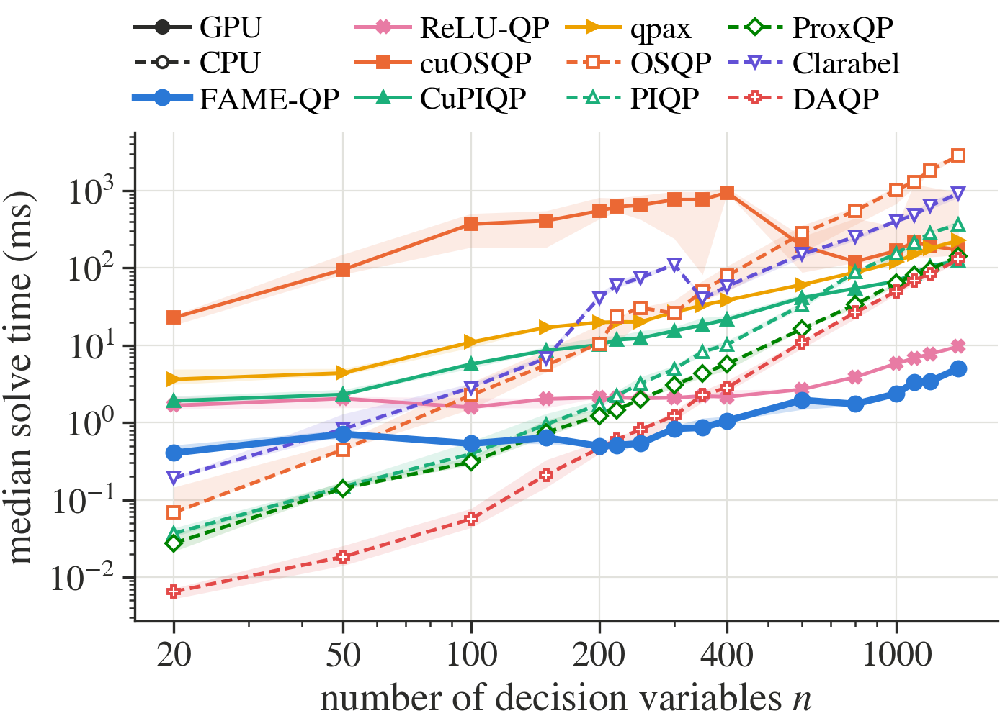

PDF: experiments/data/random_qp_cpu_gpu/figures/fig_random_qp.pdf


In [5]:
show_figure(QP_DIR / "figures/fig_random_qp.png", 600)

Numbers quoted in the text, from the mean over the five instances of their
median solve times.

In [6]:
qp = {}
for r in read_csv(QP_DIR / "processed/random_qp_mean_std.csv"):
    qp.setdefault(r["solver"], {})[int(r["n"])] = r
mean_qp = {s: {n: r["mean_ms"] for n, r in v.items()} for s, v in qp.items()}
sizes = sorted(mean_qp["fame-qp"])
fame = mean_qp["fame-qp"]
gpu = ["reluqp", "cuosqp", "cupiqp", "qpax"]
cpu = ["osqp", "piqp", "proxqp", "clarabel", "daqp"]

beats_gpu = all(fame[n] < min(mean_qp[s][n] for s in gpu) for n in sizes)
beats_cpu = [n for n in sizes if fame[n] < min(mean_qp[s][n] for s in cpu)]
first_cpu = next(n for n in sizes if all(m in beats_cpu for m in sizes if m >= n))
print(f"float64 FAME-QP faster than every GPU baseline at every size: {beats_gpu}")
print(f"faster than every CPU baseline for n >= {first_cpu}")

big = [n for n in sizes if 220 <= n <= 1400]
for s, name in (("daqp", "DAQP"), ("reluqp", "ReLU-QP")):
    sp = [mean_qp[s][n] / fame[n] for n in big]
    print(f"speedup over {name}, n = 220-1400: {min(sp):.1f}-{max(sp):.1f}x")

f32 = mean_qp["fame-qp-f32"]
print("float64 faster than float32 at n =", [n for n in sizes if fame[n] < f32[n]])
print(f"n = 1400: float32 {f32[1400]:.2f} ms, float64 {fame[1400]:.2f} ms, "
      f"cuOSQP {mean_qp['cuosqp'][1400]:.0f} ms")

float64 FAME-QP faster than every GPU baseline at every size: True
faster than every CPU baseline for n >= 220
speedup over DAQP, n = 220-1400: 1.2-25.9x
speedup over ReLU-QP, n = 220-1400: 1.5-4.3x
float64 faster than float32 at n = [600, 800]
n = 1400: float32 1.95 ms, float64 5.01 ms, cuOSQP 326 ms


## Closed-loop MPC on random linear systems (Table I)

MPC step time [ms], mean ± standard deviation over 50 closed-loop steps.

In [7]:
lmpc = {}
for r in read_csv(LMPC_DIR / "processed/random_lmpc_mean_std_warm_init.csv"):
    lmpc.setdefault(r["method"], {})[int(r["n"])] = r
ns = sorted(lmpc["fame-qp"])
order = ["fame-qp", "reluqp", "cupiqp", "cudampc", "pimpc"]
tex_name = {"fame-qp": r"\fameqp{}", "reluqp": "ReLU-QP", "cupiqp": "CuPIQP",
            "cudampc": "CUDA MPC", "pimpc": r"$\pi$MPC"}
md_name = {"fame-qp": "FAME-QP", "reluqp": "ReLU-QP", "cupiqp": "CuPIQP",
           "cudampc": "CUDA MPC", "pimpc": "πMPC"}
fastest = {n: min(lmpc, key=lambda m: lmpc[m][n]["mean_ms"]) for n in ns}


def lmpc_cell(m, n, latex=True):
    s = fmt(lmpc[m][n]["mean_ms"], lmpc[m][n]["std_ms"])
    if latex:
        return f"$\\mathbf{{{s}}}$" if fastest[n] == m else f"${s}$"
    s = s.replace("\\pm", " ± ")
    return f"**{s}**" if fastest[n] == m else s


tex = [r"\begin{tabular}{@{}lccccc@{}}", r"\toprule",
       r"Solver / $n$ & " + " & ".join(map(str, ns)) + r" \\", r"\midrule"]
for m in order:
    if m == "cudampc":
        tex.append(r"\midrule")
    tex.append(f"{tex_name[m]} & " + " & ".join(lmpc_cell(m, n) for n in ns) + r" \\")
tex += [r"\bottomrule", r"\end{tabular}"]
rows = [[md_name[m]] + [lmpc_cell(m, n, latex=False) for n in ns] for m in order]
show_table("\n".join(tex), ["Solver / n"] + [str(n) for n in ns], rows)

\begin{tabular}{@{}lccccc@{}}
\toprule
Solver / $n$ & 400 & 800 & 1200 & 1600 & 2000 \\
\midrule
\fameqp{} & $\mathbf{0.658\pm0.066}$ & $\mathbf{1.19\pm0.04}$ & $\mathbf{2.05\pm0.45}$ & $\mathbf{2.92\pm0.09}$ & $\mathbf{4.23\pm0.21}$ \\
ReLU-QP & $2.10\pm0.37$ & $6.06\pm1.02$ & $11.6\pm1.9$ & $20.0\pm3.9$ & $30.9\pm6.1$ \\
CuPIQP & $23.7\pm7.0$ & $58.9\pm11.3$ & $178\pm42$ & $248\pm63$ & $449\pm120$ \\
\midrule
CUDA MPC & $22.7\pm0.1$ & $59.9\pm0.5$ & $82.8\pm0.8$ & $103\pm0$ & $138\pm3$ \\
$\pi$MPC & $9.06\pm12.39$ & $8.90\pm12.88$ & $6.78\pm5.67$ & $15.4\pm23.9$ & $13.4\pm18.1$ \\
\bottomrule
\end{tabular}


| Solver / n | 400 | 800 | 1200 | 1600 | 2000 |
|---|---|---|---|---|---|
| FAME-QP | **0.658 ± 0.066** | **1.19 ± 0.04** | **2.05 ± 0.45** | **2.92 ± 0.09** | **4.23 ± 0.21** |
| ReLU-QP | 2.10 ± 0.37 | 6.06 ± 1.02 | 11.6 ± 1.9 | 20.0 ± 3.9 | 30.9 ± 6.1 |
| CuPIQP | 23.7 ± 7.0 | 58.9 ± 11.3 | 178 ± 42 | 248 ± 63 | 449 ± 120 |
| CUDA MPC | 22.7 ± 0.1 | 59.9 ± 0.5 | 82.8 ± 0.8 | 103 ± 0 | 138 ± 3 |
| πMPC | 9.06 ± 12.39 | 8.90 ± 12.88 | 6.78 ± 5.67 | 15.4 ± 23.9 | 13.4 ± 18.1 |

Numbers quoted in the text.

In [8]:
mean = lambda m, n: lmpc[m][n]["mean_ms"]
std = lambda m, n: lmpc[m][n]["std_ms"]
viol = lambda m: [lmpc[m][n]["max_viol"] for n in ns]

print(f"FAME-QP fastest at every size: {all(fastest[n] == 'fame-qp' for n in ns)}, "
      f"{fmt(mean('fame-qp', ns[0]))}-{fmt(mean('fame-qp', ns[-1]))} ms")
for m in ("reluqp", "pimpc"):
    sp = [mean(m, n) / mean("fame-qp", n) for n in ns]
    smaller = all(std("fame-qp", n) < std(m, n) for n in ns)
    print(f"faster than {md_name[m]}: {min(sp):.1f}-{max(sp):.1f}x; "
          f"smaller std at every size: {smaller}")

quality = read_csv(LMPC_DIR / "tables/tab_random_lmpc_warm_init_quality.csv")
dj = max(abs(r[f"dJ_pct_{m}"]) for r in quality for m in order[1:])
print(f"closed-loop costs agree within {dj:.2f} %")
print(f"largest bound violation: FAME-QP {max(viol('fame-qp')):.1e}, "
      f"ReLU-QP {min(viol('reluqp')):.1e}-{max(viol('reluqp')):.1e}, "
      f"πMPC {min(viol('pimpc')):.1e}-{max(viol('pimpc')):.1e}, "
      f"CuPIQP {max(viol('cupiqp')):.1e}, CUDA MPC {max(viol('cudampc')):.1e}")

FAME-QP fastest at every size: True, 0.658-4.23 ms
faster than ReLU-QP: 3.2-7.3x; smaller std at every size: True
faster than πMPC: 3.2-13.8x; smaller std at every size: True
closed-loop costs agree within 0.06 %
largest bound violation: FAME-QP 2.0e-03, ReLU-QP 1.4e-02-4.3e-02, πMPC 8.2e-05-1.2e-04, CuPIQP 2.2e-12, CUDA MPC 6.2e-07


## Unitree G1 push recovery (Table II and Fig. 2)

QP time per control step, mean ± standard deviation excluding the first step,
and RMS deviation of the centre of mass.

In [9]:
g1 = {}
for r in read_csv(G1_DIR / "tables/tab_g1_balance_shifted.csv"):
    g1.setdefault(int(r["N"]), {})[r["method"]] = r
Ns = sorted(g1)


def qp_cell(N, m, latex=True):
    s = fmt(g1[N][m]["qp_mean_ms"], g1[N][m]["qp_std_ms"])
    best = m == min(g1[N], key=lambda k: g1[N][k]["qp_mean_ms"])
    if latex:
        return f"$\\mathbf{{{s}}}$" if best else f"${s}$"
    s = s.replace("\\pm", " ± ")
    return f"**{s}**" if best else s


tex = [r"\begin{tabular}{@{}rcccc@{}}", r"\toprule",
       r"$N$ ($n$) & \multicolumn{2}{c}{QP time [ms]} & \multicolumn{2}{c}{CoM RMS [mm]} \\",
       r"\cmidrule(lr){2-3}\cmidrule(lr){4-5}",
       r"& \fameqp{} & ReLU-QP & \fameqp{} & ReLU-QP \\", r"\midrule"]
rows = []
for N in Ns:
    n = int(g1[N]["fame-qp"]["n"])
    rms = [f"{g1[N][m]['com_dev_rms_mm']:.1f}" for m in ("fame-qp", "reluqp")]
    tex.append(f"{N} ({n}) & {qp_cell(N, 'fame-qp')} & {qp_cell(N, 'reluqp')} & "
               f"{rms[0]} & {rms[1]} \\\\")
    rows.append([f"{N} ({n})", qp_cell(N, "fame-qp", False), qp_cell(N, "reluqp", False), *rms])
tex += [r"\bottomrule", r"\end{tabular}"]
show_table("\n".join(tex), ["N (n)", "FAME-QP [ms]", "ReLU-QP [ms]",
                            "FAME-QP CoM RMS [mm]", "ReLU-QP CoM RMS [mm]"], rows)

\begin{tabular}{@{}rcccc@{}}
\toprule
$N$ ($n$) & \multicolumn{2}{c}{QP time [ms]} & \multicolumn{2}{c}{CoM RMS [mm]} \\
\cmidrule(lr){2-3}\cmidrule(lr){4-5}
& \fameqp{} & ReLU-QP & \fameqp{} & ReLU-QP \\
\midrule
10 (290) & $\mathbf{0.650\pm0.091}$ & $1.47\pm0.05$ & 18.7 & 18.7 \\
15 (435) & $\mathbf{0.763\pm0.116}$ & $2.26\pm0.12$ & 19.1 & 19.2 \\
20 (580) & $\mathbf{1.04\pm0.20}$ & $3.25\pm0.13$ & 20.5 & 19.5 \\
\bottomrule
\end{tabular}


| N (n) | FAME-QP [ms] | ReLU-QP [ms] | FAME-QP CoM RMS [mm] | ReLU-QP CoM RMS [mm] |
|---|---|---|---|---|
| 10 (290) | **0.650 ± 0.091** | 1.47 ± 0.05 | 18.7 | 18.7 |
| 15 (435) | **0.763 ± 0.116** | 2.26 ± 0.12 | 19.1 | 19.2 |
| 20 (580) | **1.04 ± 0.20** | 3.25 ± 0.13 | 20.5 | 19.5 |

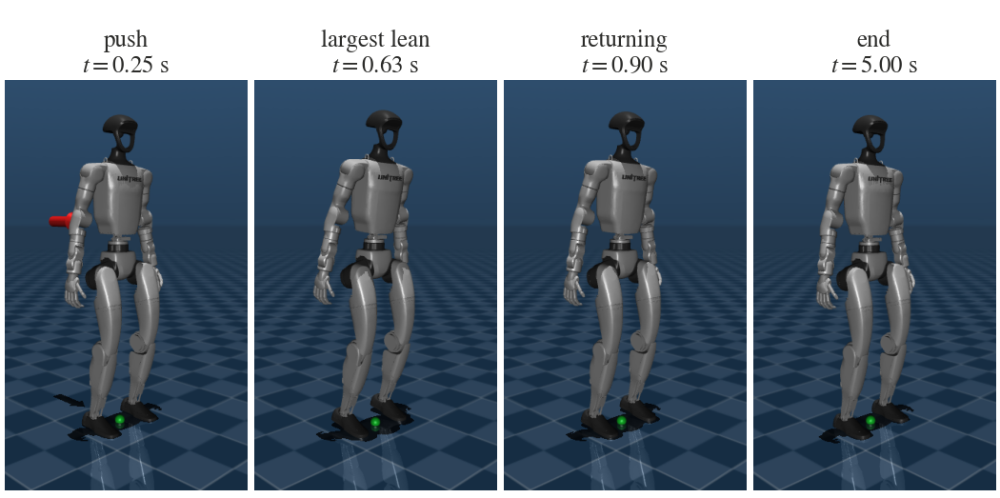

PDF: experiments/data/g1_balance_gpu/figures/fig_g1_balance_shifted.pdf


In [10]:
show_figure(G1_DIR / "figures/fig_g1_balance_shifted.png", 600, needs=G1_SCENE)

The same run as a video: the first 2.5 s, in real time, with an 80 N push at
$t = 0.2$ s. The red arrow is the push and the green dot the ground projection
of the centre of mass.

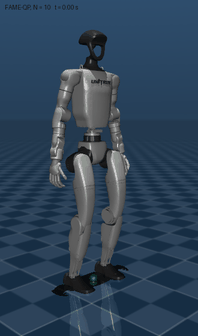

In [11]:
if G1_SCENE.exists():
    g1_script = load_script("g1_balance/g1_balance_gpu.py")
    z = np.load(G1_DIR / "raw/traj_shifted_fame-qp_N10.npz")
    t = z["t"]
    idx = np.flatnonzero(t <= 2.5)[::25]                 # 2 ms steps: 20 frames per second
    frames = g1_script.render_frames(z, idx)
    frames = [label_frame(f, f"FAME-QP, N = 10   t = {t[k]:.2f} s") for f, k in zip(frames, idx)]
    show_gif(frames, fps=20, scale=0.6)
else:
    print(f"skipped: the G1 model is missing; run\n  {FETCH}")

Numbers quoted in the text (2 ms control period).

In [12]:
sp = [g1[N]["reluqp"]["qp_mean_ms"] / g1[N]["fame-qp"]["qp_mean_ms"] for N in Ns]
print(f"FAME-QP reduces mean QP time by {min(sp):.1f}-{max(sp):.1f}x")
for m, name in (("fame-qp", "FAME-QP"), ("reluqp", "ReLU-QP")):
    over = [N for N in Ns if g1[N][m]["qp_mean_ms"] > 2.0]
    print(f"{name}: mean QP time above 2 ms for N = {over or 'none'}")
rms = [g1[N][m]["com_dev_rms_mm"] for N in Ns for m in ("fame-qp", "reluqp")]
print(f"CoM RMS deviation {min(rms):.1f}-{max(rms):.1f} mm")

FAME-QP reduces mean QP time by 2.3-3.1x
FAME-QP: mean QP time above 2 ms for N = none
ReLU-QP: mean QP time above 2 ms for N = [15, 20]
CoM RMS deviation 18.7-20.5 mm


## Skydio X2 trajectory tracking (Fig. 3)

KQ-LMPC tracking a lemniscate for 20 s with a 1.4 s horizon ($N = 70$,
$n = 280$); the QP matrices change at every step. Part 2 flies it live.

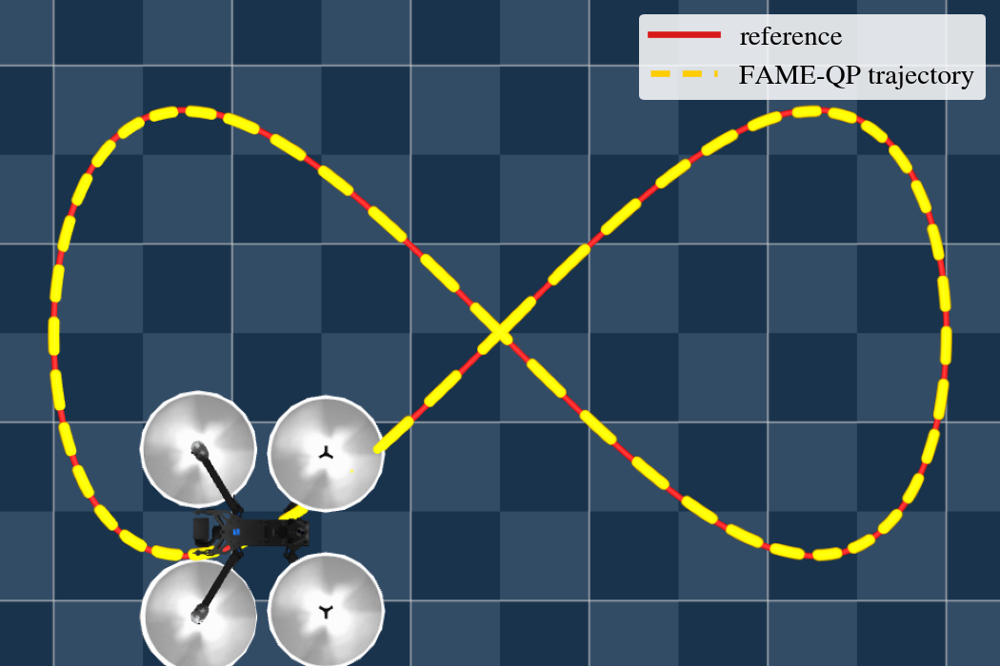

PDF: experiments/data/kqlmpc_gpu/figures/fig_kqlmpc_H1.4.pdf


In [13]:
show_figure(KQ_DIR / "figures/fig_kqlmpc_H1.4.png", 500, needs=KQ_PKG)

Numbers quoted in the text (20 ms control period).

In [14]:
kq = {r["method"]: r for r in read_csv(KQ_DIR / "tables/tab_kqlmpc_H1.4.csv")}
f, c = kq["fame-qp"], kq["cupiqp"]
print(f"mean QP time: FAME-QP {fmt(f['qp_mean_ms'], f['qp_std_ms'])} ms, "
      f"CuPIQP {fmt(c['qp_mean_ms'], c['qp_std_ms'])} ms "
      f"({c['qp_mean_ms'] / f['qp_mean_ms']:.1f}x)".replace("\\pm", " ± "))
print(f"99th percentile: FAME-QP {f['qp_p99_ms']:.1f} ms, CuPIQP {c['qp_p99_ms']:.1f} ms")
print(f"position RMSE: FAME-QP {1e3 * f['rmse_track_m']:.1f} mm, "
      f"CuPIQP {1e3 * c['rmse_track_m']:.1f} mm")
print(f"largest tracking error: FAME-QP {1e3 * f['max_err_track_m']:.1f} mm, "
      f"CuPIQP {1e3 * c['max_err_track_m']:.1f} mm")

mean QP time: FAME-QP 12.5 ± 3.2 ms, CuPIQP 59.2 ± 4.8 ms (4.7x)
99th percentile: FAME-QP 17.6 ms, CuPIQP 72.1 ms
position RMSE: FAME-QP 2.7 mm, CuPIQP 3.4 mm
largest tracking error: FAME-QP 8.5 mm, CuPIQP 8.5 mm


# Part 2: live runs

Short versions of the experiments, solved on this GPU and plotted as they
progress. They use the experiment scripts' own solver wrappers, so the
settings and the timed region are the paper's. Faded lines and bands are the
paper's results. Baselines that are not installed are skipped.

## Random dense QPs

Three sizes, five instances each, against ReLU-QP (GPU) and DAQP (the fastest
CPU solver). Each solver uses the tolerance it needed in the paper to reach
$10^{-3}$ accuracy against a Clarabel reference; FAME-QP is set up on a
held-out instance, and every time is the median of repeated cold solves.

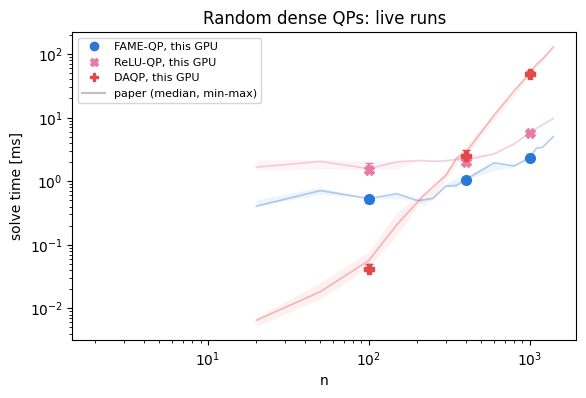

n =   100  FAME-QP      0.531 ms  (paper 0.536 ms, eps 0.0001, error 1.0e-04)
n =   100  ReLU-QP      1.508 ms  (paper 1.577 ms, eps 0.001, error 2.7e-04)
n =   100  DAQP         0.042 ms  (paper 0.057 ms, eps 0.001, error 5.1e-06)
n =   400  FAME-QP      1.038 ms  (paper 1.056 ms, eps 0.001, error 4.4e-04)
n =   400  ReLU-QP      1.982 ms  (paper 2.150 ms, eps 0.001, error 5.0e-05)
n =   400  DAQP         2.500 ms  (paper 2.826 ms, eps 0.001, error 1.6e-05)
n =  1000  FAME-QP      2.293 ms  (paper 2.364 ms, eps 0.001, error 1.0e-04)
n =  1000  ReLU-QP      5.754 ms  (paper 5.818 ms, eps 0.001, error 5.7e-05)
n =  1000  DAQP        48.860 ms  (paper 49.942 ms, eps 0.001, error 2.4e-05)


In [15]:
LIVE_SIZES = [100, 400, 1000]
rq = load_script("random_qp/random_qp_cpu_gpu.py")
SERIES = {s[0]: s for s in load_script("random_qp/viz_tab_random_qp.py").SERIES}
solvers = [s for s, mod in (("fame-qp", "torch"), ("reluqp", "reluqp"), ("daqp", "daqp"))
           if GPU and installed(mod)]
reference = installed("clarabel")

live = LiveFigure(figsize=(6.5, 4))
ax = live.ax
for s in solvers:
    _, label, _, color, marker = SERIES[s]
    ns_p = sorted(qp[s])
    ax.plot(ns_p, [qp[s][n]["median_ms"] for n in ns_p], color=color, alpha=0.35, lw=1.2)
    ax.fill_between(ns_p, [qp[s][n]["min_ms"] for n in ns_p], [qp[s][n]["max_ms"] for n in ns_p],
                    color=color, alpha=0.08, lw=0)
    ax.plot([], [], color=color, marker=marker, ls="none", label=f"{label}, this GPU")
ax.plot([], [], color="0.5", alpha=0.5, label="paper (median, min-max)")
ax.set(xscale="log", yscale="log", xlabel="n", ylabel="solve time [ms]",
       title="Random dense QPs: live runs")
ax.legend(fontsize=8, loc="upper left")
live.update()

for n in LIVE_SIZES:
    data = [rq.rand_qp(n, seed) for seed in range(rq.N_SEEDS)]
    refs = [rq.reference_solution(d)[0] for d in data] if reference else None
    for s in solvers:
        setup, solve, cold, free, _ = rq.FACTORY[s]()
        eps = qp[s][n]["eps"]
        medians, errors = [], []
        for i, d in enumerate(data):
            st = setup(d, eps)
            cold(st)
            t0 = time.perf_counter()
            x, _, _ = solve(st)
            reps, warm = rq.n_reps(time.perf_counter() - t0)
            ts = []
            for k in range(warm + reps):
                cold(st)
                t0 = time.perf_counter()
                solve(st)
                if k >= warm:
                    ts.append((time.perf_counter() - t0) * 1e3)
            medians.append(np.median(ts))
            if refs is not None:
                errors.append(np.max(np.abs(x - refs[i])))
            if free:
                free(st)
        _, label, _, color, marker = SERIES[s]
        med = np.median(medians)
        ax.errorbar([n], [med], yerr=[[med - min(medians)], [max(medians) - med]],
                    color=color, marker=marker, ms=7, capsize=3, ls="none")
        live.update()
        err = f", error {max(errors):.1e}" if errors else ""
        print(f"n = {n:5d}  {label:8s}  {med:8.3f} ms  (paper {qp[s][n]['median_ms']:.3f} ms, "
              f"eps {eps:g}{err})")

## Closed-loop MPC on random linear systems

50 closed-loop steps of the Table I problems with $n_u = 10$ and $20$
($n = 400$ and $800$), FAME-QP against ReLU-QP. As in the paper, each method
first solves at $x_0$ (untimed), and every step is timed from the data update
through the shifted warm start to the first input on the host. The 50 steps run
back to back and are drawn when they finish: redrawing between steps would
leave the GPU idle and slow the next solve.

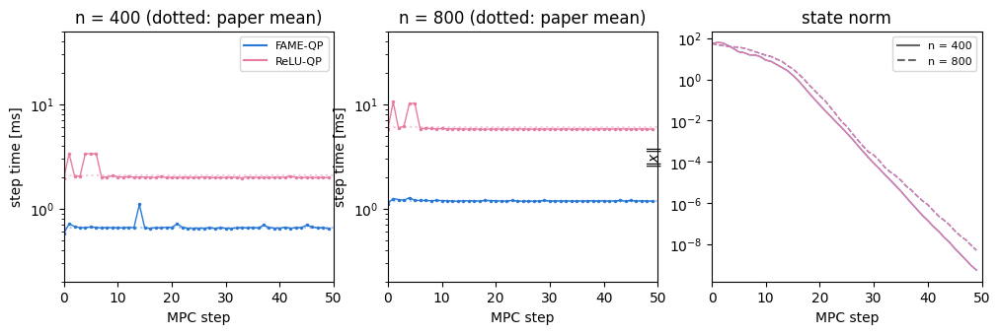

n =  400  FAME-QP  0.665 ± 0.065 ms (paper 0.658 ± 0.066 ms), largest bound violation 2.3e-06
n =  400  ReLU-QP  2.10 ± 0.37 ms (paper 2.10 ± 0.37 ms), largest bound violation 1.4e-02
n =  800  FAME-QP  1.19 ± 0.02 ms (paper 1.19 ± 0.04 ms), largest bound violation 5.0e-04
n =  800  ReLU-QP  6.06 ± 1.08 ms (paper 6.06 ± 1.02 ms), largest bound violation 2.1e-02


In [16]:
lm = load_script("random_lmpc/random_lmpc_gpu.py")
methods = [m for m, mod in (("fame-qp", "torch"), ("reluqp", "reluqp")) if GPU and installed(mod)]
NUS = [10, 20]

live = LiveFigure(1, 3, figsize=(12, 3.3))
ax_x = live.ax[2]
style = {10: "-", 20: "--"}
for ax, nu in zip(live.ax, NUS):
    n = nu * lm.HORIZON
    for m in methods:
        ax.axhline(lmpc[m][n]["mean_ms"], color=SERIES[m][3], alpha=0.4, ls=":")
        ax.plot([], [], color=SERIES[m][3], label=md_name[m])
    ax.set(yscale="log", xlim=(0, lm.STEPS), ylim=(0.2, 50), xlabel="MPC step",
           ylabel="step time [ms]", title=f"n = {n} (dotted: paper mean)")
live.ax[0].legend(fontsize=8)
for nu in NUS:
    ax_x.plot([], [], color="0.4", ls=style[nu], label=f"n = {nu * lm.HORIZON}")
ax_x.set(yscale="log", xlim=(0, lm.STEPS), xlabel="MPC step", ylabel=r"$\|x\|$",
         title="state norm")
ax_x.legend(fontsize=8)
live.update()

summary = []
for ax, nu in zip(live.ax, NUS):
    scale = lm.X0_SCALE[nu]
    ocp, d0, K = lm.build(nu)
    x0 = scale * d0
    opts = dict(start="warm", step0="init", fame_setup="heldout", x0_scale=scale)
    for m in methods:
        step = lm.MAKERS[m](ocp, K, x0, dict(opts))
        x, u_prev = x0.copy(), np.zeros(ocp.nu)
        (getattr(step, "init", None) or step.reset)(x)
        ts, xs, viol = [], [], 0.0
        for k in range(lm.STEPS):
            t0 = time.perf_counter()
            u, _ = step(x, u_prev, k)
            ts.append((time.perf_counter() - t0) * 1e3)
            viol = max(viol, float(np.max(np.maximum(np.abs(u) - ocp.umax, 0))))
            u_prev = np.clip(u, ocp.umin, ocp.umax)
            x = ocp.A @ x + ocp.B @ u_prev
            xs.append(np.linalg.norm(x))
        ax.plot(ts, color=SERIES[m][3], marker=".", ms=3, lw=1)
        ax_x.plot(xs, color=SERIES[m][3], ls=style[nu], lw=1)
        live.update()
        summary.append((nu * lm.HORIZON, m, np.mean(ts), np.std(ts, ddof=1), viol))

for n, m, mu, sd, v in summary:
    p = lmpc[m][n]
    print(f"n = {n:4d}  {md_name[m]:8s} {fmt(mu, sd)} ms (paper {fmt(p['mean_ms'], p['std_ms'])} ms), "
          f"largest bound violation {v:.1e}".replace("\\pm", " ± "))

## Skydio X2 flight in MuJoCo

The full 20 s lemniscate flight of Fig. 3 with FAME-QP, about a minute. The
flown path is drawn every 5 simulated seconds; afterwards the QP time per
control step is compared with the paper's run, and the flight is rendered as a
video.

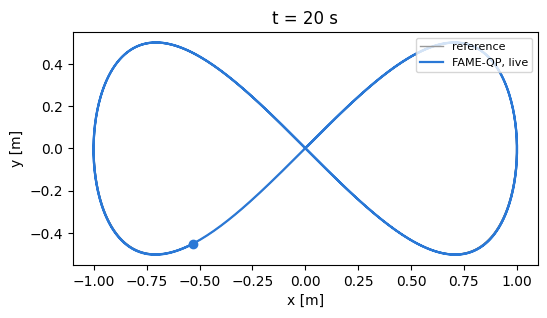

flight done in 73 s of wall time


In [17]:
flight = None
if not GPU:
    print("skipped: no CUDA GPU")
elif not KQ_PKG.exists():
    print(f"skipped: the KQ-LMPC package is missing; run\n  {FETCH}")
else:
    km = load_script("quadrotor/kqlmpc_gpu.py")
    paper_kq = km.json.load(open(KQ_DIR / "raw/kqlmpc_H1.4.json"))["results"]["fame-qp"]
    Xd = np.asarray(paper_kq["traj"]["Xd"])
    QPOS, PLANT = [], {}

    live = LiveFigure(figsize=(6, 3.4))
    ax = live.ax
    ax.plot(Xd[0], Xd[1], color="0.6", lw=1, label="reference")
    path, = ax.plot([], [], color=SERIES["fame-qp"][3], lw=1.6, label="FAME-QP, live")
    dot, = ax.plot([], [], "o", color=SERIES["fame-qp"][3])
    ax.set(aspect="equal", xlabel="x [m]", ylabel="y [m]", title="t = 0 s")
    ax.legend(fontsize=8, loc="upper right")
    live.update()

    load_demo = km.load_demo

    def load_recording_demo():
        demo = load_demo()

        class RecordingX2(demo.SkydioX2):
            def __init__(self, *args, **kwargs):
                super().__init__(*args, **kwargs)
                PLANT["plant"] = self

            def step(self, dt):
                super().step(dt)
                QPOS.append(self.data.qpos.copy())
                if len(QPOS) % 250 == 0:                 # every 5 simulated seconds
                    P = np.array(QPOS)
                    path.set_data(P[:, 0], P[:, 1])
                    dot.set_data(P[-1:, 0], P[-1:, 1])
                    ax.set_title(f"t = {len(QPOS) * dt:.0f} s")
                    live.update()

        demo.SkydioX2 = RecordingX2
        return demo

    km.load_demo = load_recording_demo
    try:
        t0 = time.time()
        flight = km.fly("fame-qp", km.HORIZON, km.TSIM)
    finally:
        km.load_demo = load_demo
    print(f"flight done in {time.time() - t0:.0f} s of wall time")

In [18]:
if flight is not None:
    ms = [s["ms"] for s in flight["step_log"]]
    ms_paper = [s["ms"] for s in paper_kq["step_log"]]
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.plot(np.arange(len(ms_paper)) * 0.02, ms_paper, color="0.6", lw=0.8, label="paper")
    ax.plot(np.arange(len(ms)) * 0.02, ms, color=SERIES["fame-qp"][3], lw=0.8, label="this GPU")
    ax.axhline(20, color="k", ls=":", lw=1, label="control period")
    ax.set(xlabel="t [s]", ylabel="QP time [ms]", title="FAME-QP time per control step")
    ax.legend(fontsize=8, ncol=3)
    plt.show()
    for key, label, unit, k in (("qp_mean_ms", "mean QP time", "ms", 1),
                                ("qp_p99_ms", "99th percentile", "ms", 1),
                                ("rmse_track_m", "position RMSE", "mm", 1e3),
                                ("max_err_track_m", "largest error", "mm", 1e3)):
        print(f"{label:16s} {k * flight[key]:6.1f} {unit} (paper {k * paper_kq[key]:.1f} {unit})")

mean QP time       13.7 ms (paper 12.5 ms)
99th percentile    20.5 ms (paper 17.6 ms)
position RMSE       2.6 mm (paper 2.7 mm)
largest error       8.5 mm (paper 8.5 mm)


/tmp/ipykernel_458057/1418315799.py:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


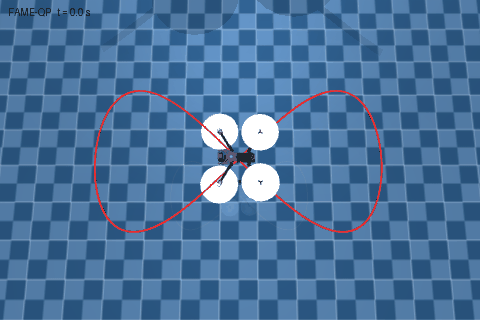

In [21]:
if flight is not None:
    import mujoco
    plant = PLANT["plant"]
    model, data = plant.model, plant.data
    W, H = 480, 320
    model.vis.global_.offwidth = max(model.vis.global_.offwidth, W)
    model.vis.global_.offheight = max(model.vis.global_.offheight, H)
    cam = mujoco.MjvCamera()
    mujoco.mjv_defaultFreeCamera(model, cam)
    cam.lookat[:] = [Xd[0].mean(), Xd[1].mean(), Xd[2].mean() - 0.1]
    cam.distance, cam.azimuth, cam.elevation = 2.8, 90.0, -80.0
    P = np.array(QPOS)
    renderer = mujoco.Renderer(model, height=H, width=W, max_geom=20000)
    frames = []
    for k in range(0, len(QPOS), 5):                      # 20 ms steps: 10 frames per second
        data.qpos[:] = QPOS[k]
        data.qvel[:] = 0
        mujoco.mj_forward(model, data)
        renderer.update_scene(data, cam)
        km._segments(renderer.scene, Xd.T[::4], km.REF_RGBA, 0.006)
        km._segments(renderer.scene, P[: k + 1 : 2, :3], km.TRJ_RGBA, 0.01)
        frames.append(label_frame(renderer.render().copy(), f"FAME-QP   t = {(k + 1) * 0.02:.1f} s"))
    renderer.close()
    show_gif(frames, fps=10)

## Full tables

The scripts also write fuller LaTeX tables with every solver and metric:

In [22]:
for p in sorted(DATA.glob("*/tables/*.tex")):
    print(rel(p))

experiments/data/g1_balance_gpu/tables/tab_g1_balance_shifted.tex
experiments/data/kqlmpc_gpu/tables/tab_kqlmpc_H1.4.tex
experiments/data/random_lmpc_gpu/tables/tab_random_lmpc_warm_init.tex
experiments/data/random_lmpc_gpu/tables/tab_random_lmpc_warm_init_quality.tex
experiments/data/random_qp_cpu_gpu/tables/tab_random_qp.tex
